In [1]:
import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import os
import random
from pathlib import Path

In [2]:

# this is for Local Binary Patterns
    
def get_pixel(img, center, x, y):
    
    new_value = 0
    
    try:
        # If local neighbourhood pixel 
        # value is greater than or equal
        # to center pixel values then 
        # set it to 1
        if img[x][y] >= center:
            new_value = 1
            
    except:
        # Exception is required when 
        # neighbourhood value of a center
        # pixel value is null i.e. values
        # present at boundaries.
        pass
    
    return new_value
 
# Function for calculating LBP
def lbp_calculated_pixel(img, x, y):
 
    center = img[x][y]
 
    val_ar = []
    
    # top_left
    val_ar.append(get_pixel(img, center, x-1, y-1))
    
    # top
    val_ar.append(get_pixel(img, center, x-1, y))
    
    # top_right
    val_ar.append(get_pixel(img, center, x-1, y + 1))
    
    # right
    val_ar.append(get_pixel(img, center, x, y + 1))
    
    # bottom_right
    val_ar.append(get_pixel(img, center, x + 1, y + 1))
    
    # bottom
    val_ar.append(get_pixel(img, center, x + 1, y))
    
    # bottom_left
    val_ar.append(get_pixel(img, center, x + 1, y-1))
    
    # left
    val_ar.append(get_pixel(img, center, x, y-1))
     
    # Now, we need to convert binary
    # values to decimal
    power_val = [1, 2, 4, 8, 16, 32, 64, 128]
 
    val = 0
    
    for i in range(len(val_ar)):
        val += val_ar[i] * power_val[i]
        
    return val
 

 


In [17]:
path = r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\raw\raw\ClientRaw\0007\0007_00_00_01_160.jpg"
img_bgr = cv2.imread(path, 1)
 
height, width = (256, 256)
 
# We need to convert RGB image 
# into gray one because gray 
# image has one channel only.
img_gray = cv2.cvtColor(img_bgr,
                        cv2.COLOR_BGR2GRAY)

img_gray = cv2.resize(img_gray, (height, width), interpolation=cv2.INTER_LINEAR) # resized
 
# Create a numpy array as 
# the same height and width 
# of RGB image
img_lbp = np.zeros((height, width),
                   np.uint8)
 
for i in range(0, height):
    for j in range(0, width):
        img_lbp[i, j] = lbp_calculated_pixel(img_gray, i, j)

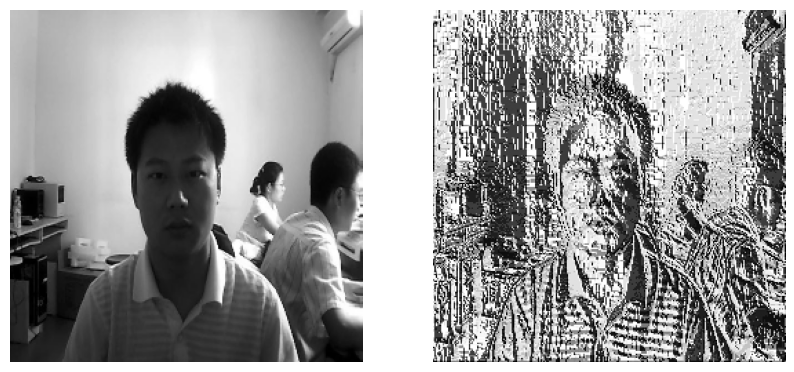

In [18]:
fig, axs = plt.subplots(figsize=(10, 5), nrows=1, ncols=2)
axs[1].imshow(img_lbp, cmap="gray")
axs[1].axis(False)
axs[0].imshow(cv2.cvtColor(img_gray, cv2.COLOR_BGR2RGB), cmap="viridis")
axs[0].axis(False)
plt.show()

## histogram 

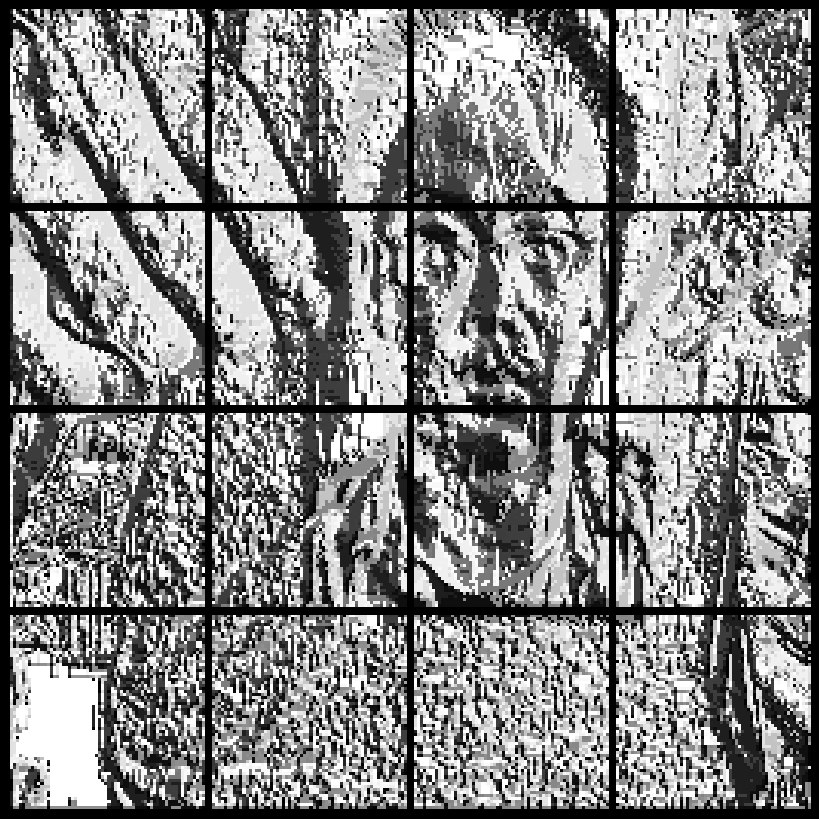

In [4]:

grid = 4  
blocks = [b for rows in np.array_split(img_lbp, grid, axis=0)
            for b in np.array_split(rows, grid, axis=1)]



grid = 4 # 4 x 4 = 16 blocks
fig, axs = plt.subplots(grid, grid, figsize=(8, 8), facecolor="black")
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.04, hspace=0.04)
for ax, block in zip(axs.ravel(), blocks):
    ax.imshow(block, cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
plt.show()



grid = 4  
hists = []

for rows in np.array_split(img_lbp, grid, axis=0):
    for block in np.array_split(rows, grid, axis=1):
        h, _ = np.histogram(block.ravel(), bins=256, range=(0, 256))
        hists.append(h / block.size)       # normalised so every block sums to 1

feature_vector = np.concatenate(hists)     # shape (16 * 256,) = (4096,)

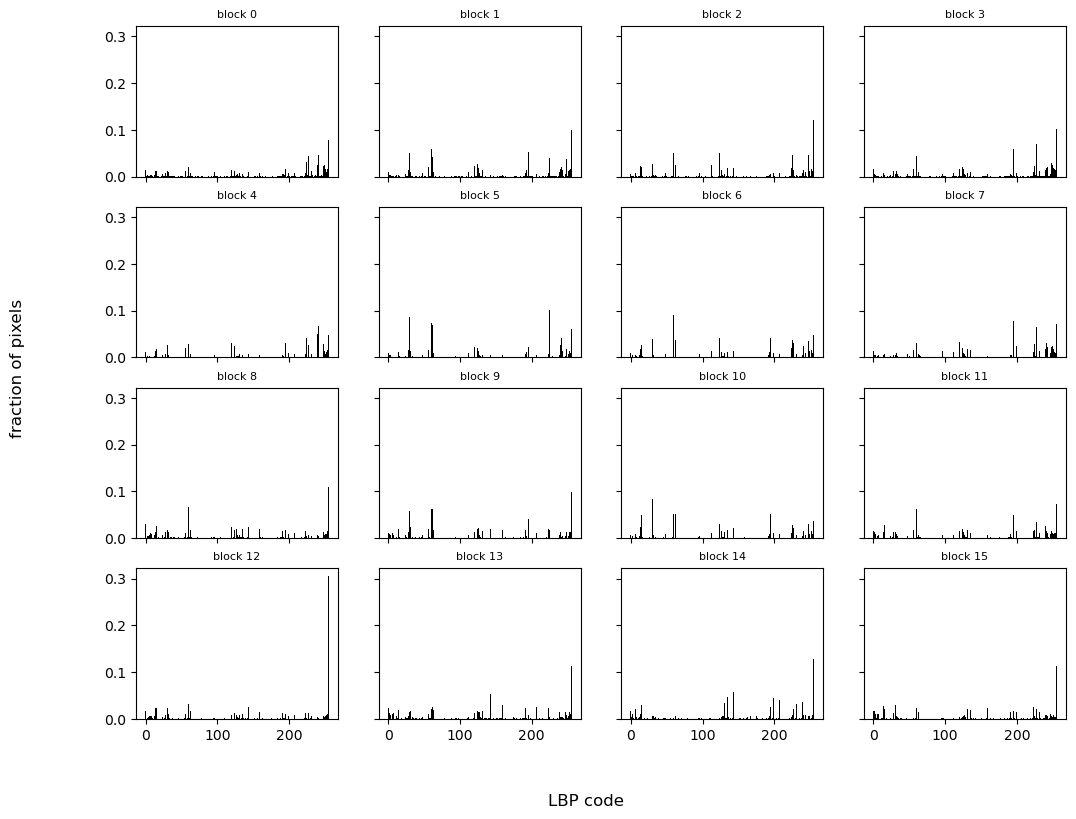

In [5]:
# plot histograms 
blocks = [b for rows in np.array_split(img_lbp, grid, axis=0)
            for b in np.array_split(rows, grid, axis=1)]

fig, axs = plt.subplots(grid, grid, figsize=(12, 9), sharex=True, sharey=True)
for k, (ax, block) in enumerate(zip(axs.ravel(), blocks)):
    h, _ = np.histogram(block.ravel(), bins=256, range=(0, 256))
    ax.bar(np.arange(256), h / block.size, width=1.0, color="k")
    ax.set_title(f"block {k}", fontsize=8)
fig.supxlabel("LBP code")
fig.supylabel("fraction of pixels")
# fig.tight_layout()
plt.show()

In [6]:
# do for all images and save to a csv, open in pandas and randomly add labels
from lbp_dataset import get_lbp_and_histogram

data_path = r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\cfd\cfd\CFD Version 3.0.1\Images\CFD-MR"
lbp, hists = get_lbp_and_histogram(path)

In [13]:
# process data for all images in dataset
data_path = Path(r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\cfd\cfd\CFD Version 3.0.1\Images\CFD-MR")

data = {
    "image" : [],
    "hists" : [],
    "type" : [], # random real or spoof
}

for i, image in enumerate (os.listdir(data_path)):
    lbp, hists = get_lbp_and_histogram(data_path / image)
    data["image"].append(image)
    data["hists"].append(hists)
    data["type"].append(random.randint(0, 1))
    

In [14]:
data_df = pd.DataFrame(data)
data_df

,image,hists,type
0,CFD-MF-300-002-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0
1,CFD-MF-301-024-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1
2,CFD-MF-302-027-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1
3,CFD-MF-303-013-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0
4,CFD-MF-304-018-N.jpg,"[0.0, 0.00048828125, 0.0, 0.0, 0.0, 0.0, 0.000...",0
...,...,...,...
83,CFD-MM-321-021-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1
84,CFD-MM-322-002-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1
85,CFD-MM-323-053-N.jpg,"[0.000244140625, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",0
86,CFD-MM-324-069-N.jpg,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0


### Classifier

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = np.stack(data_df["hists"].to_numpy())
y = data_df["type"].to_numpy()

print(X.shape, y.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, shuffle=True, test_size=0.2)

lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
lr_model.score(X_train, y_train)

(88, 4096) (88,)


0.6571428571428571

In [16]:
_, test_hist = get_lbp_and_histogram(path)
test_hist = test_hist[np.newaxis, ...]
result = lr_model.predict(test_hist)
result.item()

0

In [7]:
## working on dataset
dataset_path = Path(r"C:\Users\bamilosin\Documents\500L\coursework\cpe503 - embedded sys\raw\raw")
real_train_dataset_path = dataset_path / "client_train_raw.txt"
real_test_dataset_path = dataset_path / "client_test_raw.txt"

spoof_train_dataset_path = dataset_path / "imposter_train_raw.txt"
spoof_test_dataset_path = dataset_path / "imposter_test_raw.txt"

real_images = dataset_path / "ClientRaw"
spoof_images = dataset_path / "ImposterRaw"


In [8]:
# load training dataset
with open(real_test_dataset_path, "r") as file:
    content = file.read()
    print(content)

0010\0010_01_05_03_115.jpg
0010\0010_01_05_03_121.jpg
0010\0010_01_05_03_125.jpg
0010\0010_01_05_03_129.jpg
0010\0010_01_05_03_131.jpg
0010\0010_01_05_03_132.jpg
0010\0010_01_05_03_133.jpg
0010\0010_01_05_03_135.jpg
0010\0010_01_05_03_136.jpg
0010\0010_01_05_03_140.jpg
0010\0010_01_05_03_141.jpg
0010\0010_01_05_03_192.jpg
0010\0010_01_05_03_240.jpg
0010\0010_01_05_03_241.jpg
0010\0010_01_05_03_243.jpg
0010\0010_01_05_03_244.jpg
0010\0010_01_05_03_247.jpg
0010\0010_01_05_03_254.jpg
0010\0010_01_05_03_260.jpg
0010\0010_01_05_03_265.jpg
0010\0010_01_05_03_266.jpg
0010\0010_01_05_03_267.jpg
0010\0010_01_05_03_268.jpg
0010\0010_01_05_03_269.jpg
0010\0010_01_05_03_278.jpg
0010\0010_01_05_03_281.jpg
0010\0010_01_05_03_287.jpg
0010\0010_01_05_03_288.jpg
0010\0010_01_05_03_290.jpg
0010\0010_01_05_03_30.jpg
0010\0010_01_05_03_304.jpg
0010\0010_01_05_03_306.jpg
0010\0010_01_05_03_308.jpg
0010\0010_01_05_03_31.jpg
0010\0010_01_05_03_311.jpg
0010\0010_01_05_03_314.jpg
0010\0010_01_05_03_319.jpg
001

In [9]:
from lbp_dataset import REAL_LABEL, SPOOF_LABEL, prepare_nuaa_datasets

train_df, test_df, skipped = prepare_nuaa_datasets(
    real_train_path=real_train_dataset_path,
    real_test_path=real_test_dataset_path,
    spoof_train_path=spoof_train_dataset_path,
    spoof_test_path=spoof_test_dataset_path,
    real_images_dir=real_images,
    spoof_images_dir=spoof_images,
)

data_df = pd.concat(
    [train_df.assign(split="train"), test_df.assign(split="test")],
    ignore_index=True,
)

print(
    f"Train samples: {len(train_df)} "
    f"(real={sum(train_df['type'] == REAL_LABEL)}, spoof={sum(train_df['type'] == SPOOF_LABEL)})"
)
print(
    f"Test samples:  {len(test_df)} "
    f"(real={sum(test_df['type'] == REAL_LABEL)}, spoof={sum(test_df['type'] == SPOOF_LABEL)})"
)
print(f"Skipped:       train={len(skipped['train'])}, test={len(skipped['test'])}")
train_df.head()

Building training split...
Processed 500/3491 images...
Processed 1000/3491 images...
Processed 1500/3491 images...
Processed 2000/3491 images...
Processed 2500/3491 images...
Processed 3000/3491 images...
Building test split...
Processed 500/9123 images...
Processed 1000/9123 images...
Processed 1500/9123 images...
Processed 2000/9123 images...
Processed 2500/9123 images...
Processed 3000/9123 images...
Processed 3500/9123 images...
Processed 4000/9123 images...
Processed 4500/9123 images...
Processed 5000/9123 images...
Processed 5500/9123 images...
Processed 6000/9123 images...
Processed 6500/9123 images...
Processed 7000/9123 images...
Processed 7500/9123 images...
Processed 8000/9123 images...
Processed 8500/9123 images...
Processed 9000/9123 images...
Train samples: 3491 (real=1743, spoof=1748)
Test samples:  9123 (real=3362, spoof=5761)
Skipped:       train=0, test=0


,image,hists,type
0,ClientRaw/0001/0001_00_00_01_0.jpg,"[0.01611328125, 0.003173828125, 0.0068359375, ...",1
1,ClientRaw/0001/0001_00_00_01_101.jpg,"[0.015380859375, 0.00390625, 0.00537109375, 0....",1
2,ClientRaw/0001/0001_00_00_01_105.jpg,"[0.01513671875, 0.003173828125, 0.0029296875, ...",1
3,ClientRaw/0001/0001_00_00_01_109.jpg,"[0.014404296875, 0.0029296875, 0.00439453125, ...",1
4,ClientRaw/0001/0001_00_00_01_112.jpg,"[0.0166015625, 0.001708984375, 0.0048828125, 0...",1


In [10]:
train_df

,image,hists,type
0,ClientRaw/0001/0001_00_00_01_0.jpg,"[0.01611328125, 0.003173828125, 0.0068359375, ...",1
1,ClientRaw/0001/0001_00_00_01_101.jpg,"[0.015380859375, 0.00390625, 0.00537109375, 0....",1
2,ClientRaw/0001/0001_00_00_01_105.jpg,"[0.01513671875, 0.003173828125, 0.0029296875, ...",1
3,ClientRaw/0001/0001_00_00_01_109.jpg,"[0.014404296875, 0.0029296875, 0.00439453125, ...",1
4,ClientRaw/0001/0001_00_00_01_112.jpg,"[0.0166015625, 0.001708984375, 0.0048828125, 0...",1
...,...,...,...
3486,ImposterRaw/0008/0008_00_04_02_462.jpg,"[0.015380859375, 0.002197265625, 0.01000976562...",0
3487,ImposterRaw/0008/0008_00_04_02_485.jpg,"[0.028564453125, 0.004638671875, 0.01391601562...",0
3488,ImposterRaw/0008/0008_00_04_02_55.jpg,"[0.02294921875, 0.003662109375, 0.013427734375...",0
3489,ImposterRaw/0008/0008_00_04_02_73.jpg,"[0.01513671875, 0.0029296875, 0.0068359375, 0....",0


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train = np.stack(train_df["hists"].to_numpy())
y_train = train_df["type"].to_numpy()

X_test = np.stack(test_df["hists"].to_numpy())
y_test = test_df["type"].to_numpy()

print("Train shapes:", X_train.shape, y_train.shape)
print("Test shapes: ", X_test.shape, y_test.shape)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

train_acc = lr_model.score(X_train, y_train)
y_pred = lr_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print(f"Train accuracy: {train_acc:.4f}")
print(f"Test accuracy:  {test_acc:.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(
    "\nClassification Report:\n",
    classification_report(y_test, y_pred, target_names=["spoof (0)", "real (1)"]),
)

Train shapes: (3491, 4096) (3491,)
Test shapes:  (9123, 4096) (9123,)
Train accuracy: 0.9911
Test accuracy:  0.7666

Confusion Matrix:
 [[5079  682]
 [1447 1915]]

Classification Report:
               precision    recall  f1-score   support

   spoof (0)       0.78      0.88      0.83      5761
    real (1)       0.74      0.57      0.64      3362

    accuracy                           0.77      9123
   macro avg       0.76      0.73      0.73      9123
weighted avg       0.76      0.77      0.76      9123



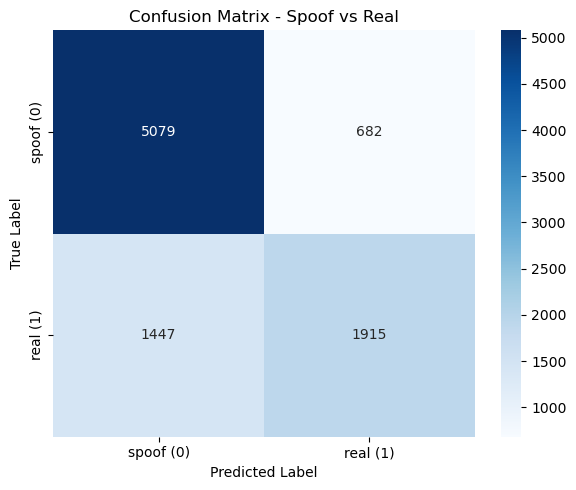

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, 
            annot=True,           # show numbers
            fmt='d',              # integer format
            cmap='Blues',
            xticklabels=["spoof (0)", "real (1)"],
            yticklabels=["spoof (0)", "real (1)"])

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Spoof vs Real")
plt.tight_layout()
plt.show()

In [14]:
lr_model.coef_, lr_model.intercept_

(array([[ 0.16224583, -0.06742869, -0.22251206, ...,  0.26637916,
          0.19606518,  0.66440797]], shape=(1, 4096)),
 array([-1.12072809]))

In [15]:
import numpy as np

W_FRAC = 10
w = lr_model.coef_[0]
print("max |w| =", np.abs(w).max())          # must be below 32

wq = np.clip(np.round(w * 2**W_FRAC), -32768, 32767).astype(int)
with open("svm_weights.mem", "w") as f:
    for v in wq:
        f.write(f"{v & 0xFFFF:04x}\n")

bias = int(round(lr_model.intercept_[0] * 2**(14 + W_FRAC)))
print("BIAS =", bias)

max |w| = 4.366885968128104
BIAS = -18802697


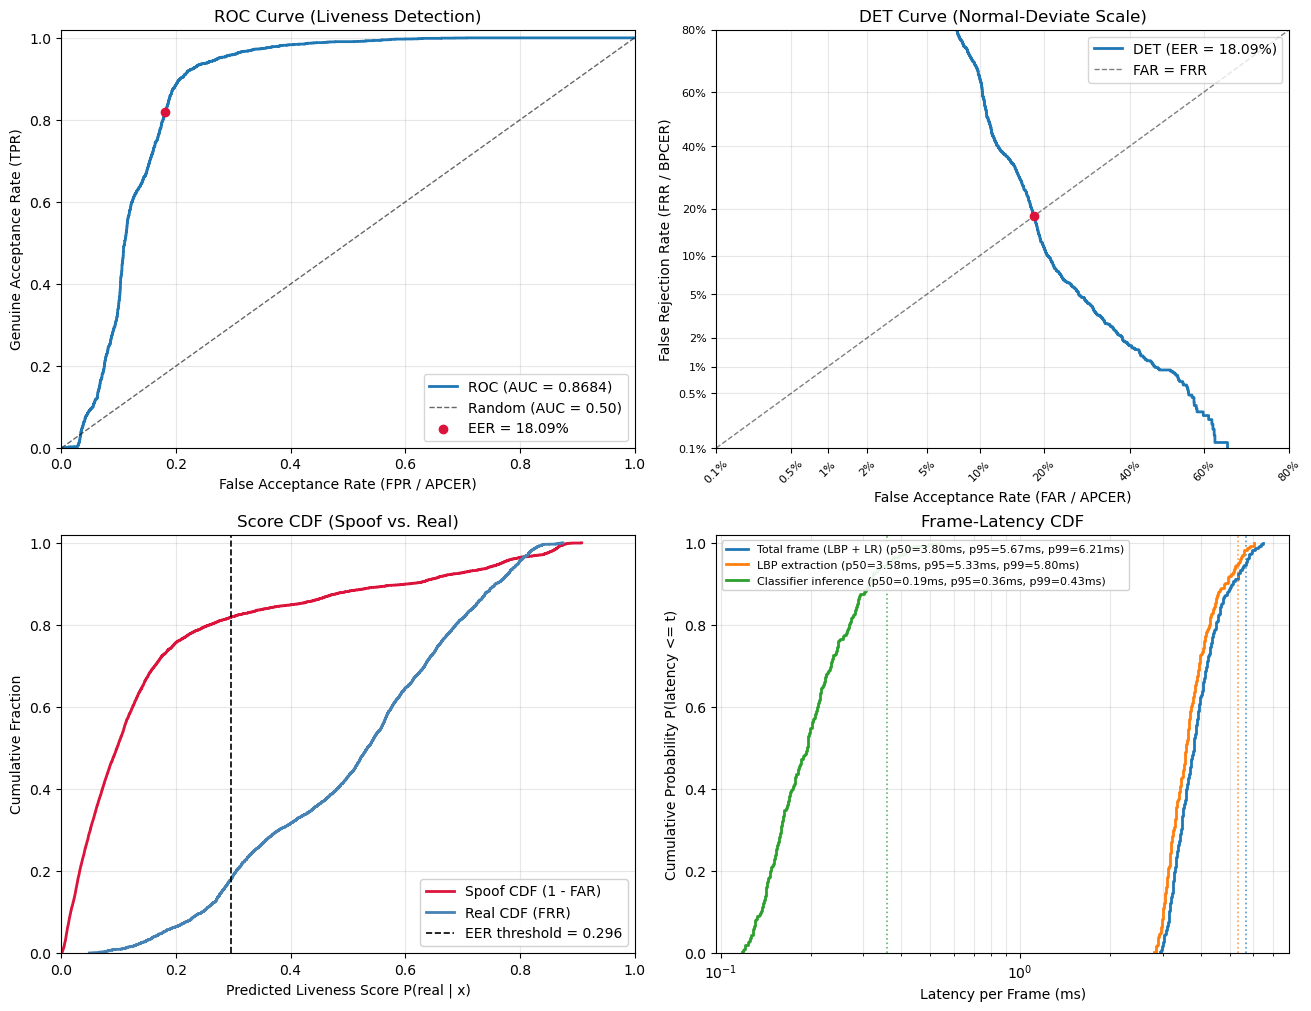

{'roc_auc': 0.8684419873483116,
 'eer': 0.18085805588687848,
 'eer_threshold': 0.29630027513730506,
 'Total frame (LBP + LR)_p50_ms': 3.7996999999450054,
 'Total frame (LBP + LR)_p95_ms': 5.665534996660426,
 'Total frame (LBP + LR)_p99_ms': 6.210690000298199,
 'LBP extraction_p50_ms': 3.5764500025834423,
 'LBP extraction_p95_ms': 5.3293599958124105,
 'LBP extraction_p99_ms': 5.796096994599792,
 'Classifier inference_p50_ms': 0.19459999748505652,
 'Classifier inference_p95_ms': 0.36052000177733134,
 'Classifier inference_p99_ms': 0.4293740011780754}

In [13]:
from evaluation_curves import benchmark_frame_latencies, plot_liveness_and_latency_curves

y_scores = lr_model.predict_proba(X_test)[:, 1]
latencies = benchmark_frame_latencies(test_df, dataset_path, lr_model, n_samples=300)
metrics_summary = plot_liveness_and_latency_curves(y_test, y_scores, latencies)
metrics_summary

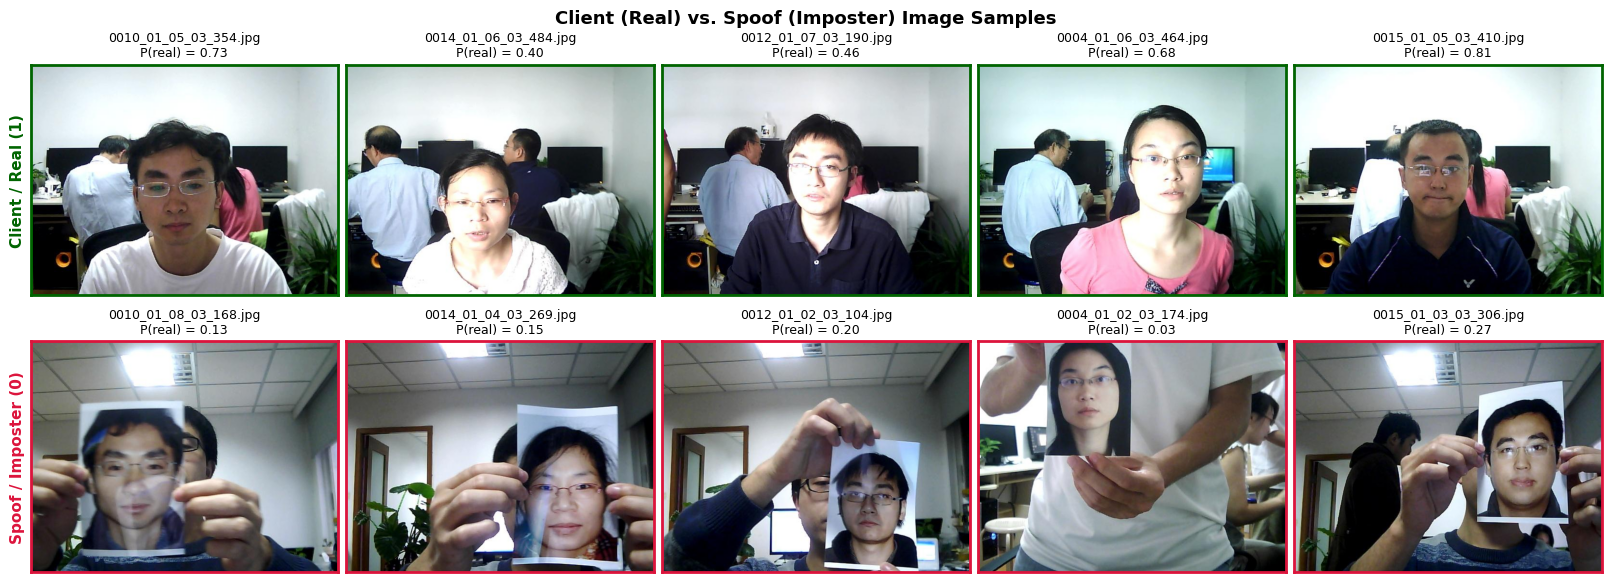

In [16]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


def plot_spoof_vs_client_samples(
    df: pd.DataFrame,
    dataset_path: str | Path,
    n_samples: int = 5,
    model=None,
    seed: int = 42,
    match_subjects: bool = True,
) -> None:
    """Plot a 2-row grid comparing Client (type=1) and Spoof (type=0) samples."""
    root = Path(dataset_path)
    rng = np.random.default_rng(seed)

    client_df = df[df["type"] == 1].copy()
    spoof_df = df[df["type"] == 0].copy()

    def _subject_id(val: str) -> str:
        parts = val.replace("\\", "/").split("/")
        return parts[-2] if len(parts) >= 2 else ""

    if match_subjects:
        client_df["_subj"] = client_df["image"].map(_subject_id)
        spoof_df["_subj"] = spoof_df["image"].map(_subject_id)
        common = sorted(s for s in (set(client_df["_subj"]) & set(spoof_df["_subj"])) if s)
    else:
        common = []

    if len(common) >= n_samples:
        chosen_subjs = rng.choice(common, size=n_samples, replace=False)
        client_rows = [
            client_df[client_df["_subj"] == s].sample(1, random_state=int(rng.integers(1e6))).iloc[0]
            for s in chosen_subjs
        ]
        spoof_rows = [
            spoof_df[spoof_df["_subj"] == s].sample(1, random_state=int(rng.integers(1e6))).iloc[0]
            for s in chosen_subjs
        ]
    else:
        k = min(n_samples, len(client_df), len(spoof_df))
        if k == 0:
            raise ValueError("Both client (type=1) and spoof (type=0) samples are required.")
        client_rows = [row for _, row in client_df.sample(k, random_state=seed).iterrows()]
        spoof_rows = [row for _, row in spoof_df.sample(k, random_state=seed).iterrows()]

    cols = len(client_rows)
    fig, axes = plt.subplots(2, cols, figsize=(3.2 * cols, 5.8), constrained_layout=True)
    if cols == 1:
        axes = axes[:, np.newaxis]

    row_specs = [
        ("Client / Real (1)", client_rows, "darkgreen"),
        ("Spoof / Imposter (0)", spoof_rows, "crimson"),
    ]
    for r, (row_label, rows, color) in enumerate(row_specs):
        for c, row in enumerate(rows):
            ax = axes[r, c]
            img_bgr = cv2.imread(str(root / row["image"]))
            if img_bgr is not None:
                ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
            else:
                ax.text(0.5, 0.5, "Missing image", ha="center", va="center")

            title = Path(row["image"]).name
            if model is not None and "hists" in row:
                prob = float(model.predict_proba(row["hists"][np.newaxis, :])[0, 1])
                title = f"{title}\nP(real) = {prob:.2f}"

            ax.set_title(title, fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_edgecolor(color)
                spine.set_linewidth(2)
            if c == 0:
                ax.set_ylabel(row_label, fontsize=11, fontweight="bold", color=color)

    fig.suptitle("Client (Real) vs. Spoof (Imposter) Image Samples", fontsize=13, fontweight="bold")
    plt.show()


# Example usage in your notebook:
# Match the same subject in each column and show model scores
plot_spoof_vs_client_samples(test_df, dataset_path, n_samples=5, model=lr_model)

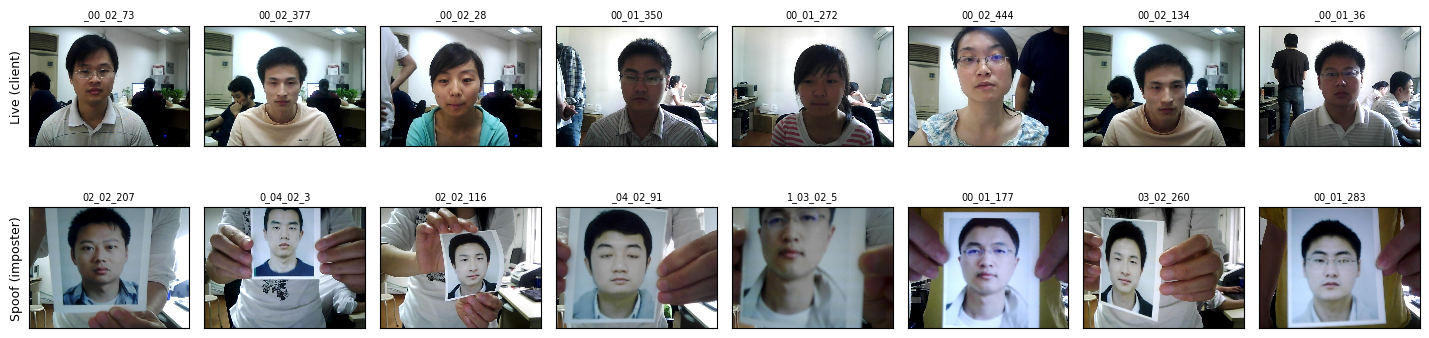

In [25]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# folder that CONTAINS ClientRaw/ and ImposterRaw/
DATA_ROOT = Path(r"C:\path\to\your\dataset")

def read_image(path):
    """Handles non-ASCII Windows paths; returns None if the file is missing/unreadable."""
    try:
        data = np.fromfile(str(path), dtype=np.uint8)
    except OSError:
        return None
    return cv2.imdecode(data, cv2.IMREAD_UNCHANGED) if data.size else None

def plot_samples(df, root, n_per_class=8, seed=0, label_col="type", path_col="image"):
    classes = [(1, "Live (client)"), (0, "Spoof (imposter)")]
    fig, axs = plt.subplots(len(classes), n_per_class,
                            figsize=(1.8 * n_per_class, 4.2), squeeze=False)
    for r, (cls, name) in enumerate(classes):
        sub = df[df[label_col] == cls]
        pick = sub.sample(min(n_per_class, len(sub)), random_state=seed)
        for c in range(n_per_class):
            ax = axs[r, c]
            ax.set_xticks([]); ax.set_yticks([])
            if c >= len(pick):
                ax.axis("off"); continue
            rel = pick.iloc[c][path_col]
            img = read_image(Path(root) / rel)
            if img is None:
                ax.text(0.5, 0.5, "not found", ha="center", va="center",
                        fontsize=8, transform=ax.transAxes)
            elif img.ndim == 2:
                ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
            else:
                ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), interpolation="nearest")
            ax.set_title(Path(rel).stem[-9:], fontsize=7)
            if c == 0:
                ax.set_ylabel(f"{name}", fontsize=9)
    fig.tight_layout()
    return fig

fig = plot_samples(train_df, dataset_path, n_per_class=8)
plt.show()